In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.neighbors import KNeighborsRegressor


from sklearn.svm import SVR

In [ ]:
df = pd.read_csv('Dataset .csv')

In [3]:
display(df.head())
df.info()
display(df.describe())
print('---------------------------------------------------------------------------------------')
print('Duplicates:', df.duplicated().sum())

print('---------------------------------------------------------------------------------------')

print('Missing values:\n', df.isnull().sum())

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

,Restaurant ID,Country Code,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
count,9.551000e+03,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000
mean,9.051128e+06,18.365616,64.126574,25.854381,1199.210763,1.804837,2.666370,156.909748
std,8.791521e+06,56.750546,41.467058,11.007935,16121.183073,0.905609,1.516378,430.169145
min,5.300000e+01,1.000000,-157.948486,-41.330428,0.000000,1.000000,0.000000,0.000000
25%,3.019625e+05,1.000000,77.081343,28.478713,250.000000,1.000000,2.500000,5.000000
50%,6.004089e+06,1.000000,77.191964,28.570469,400.000000,2.000000,3.200000,31.000000
75%,1.835229e+07,1.000000,77.282006,28.642758,700.000000,2.000000,3.700000,131.000000
max,1.850065e+07,216.000000,174.832089,55.976980,800000.000000,4.000000,4.900000,10934.000000


---------------------------------------------------------------------------------------
Duplicates: 0
---------------------------------------------------------------------------------------
Missing values:
 Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64


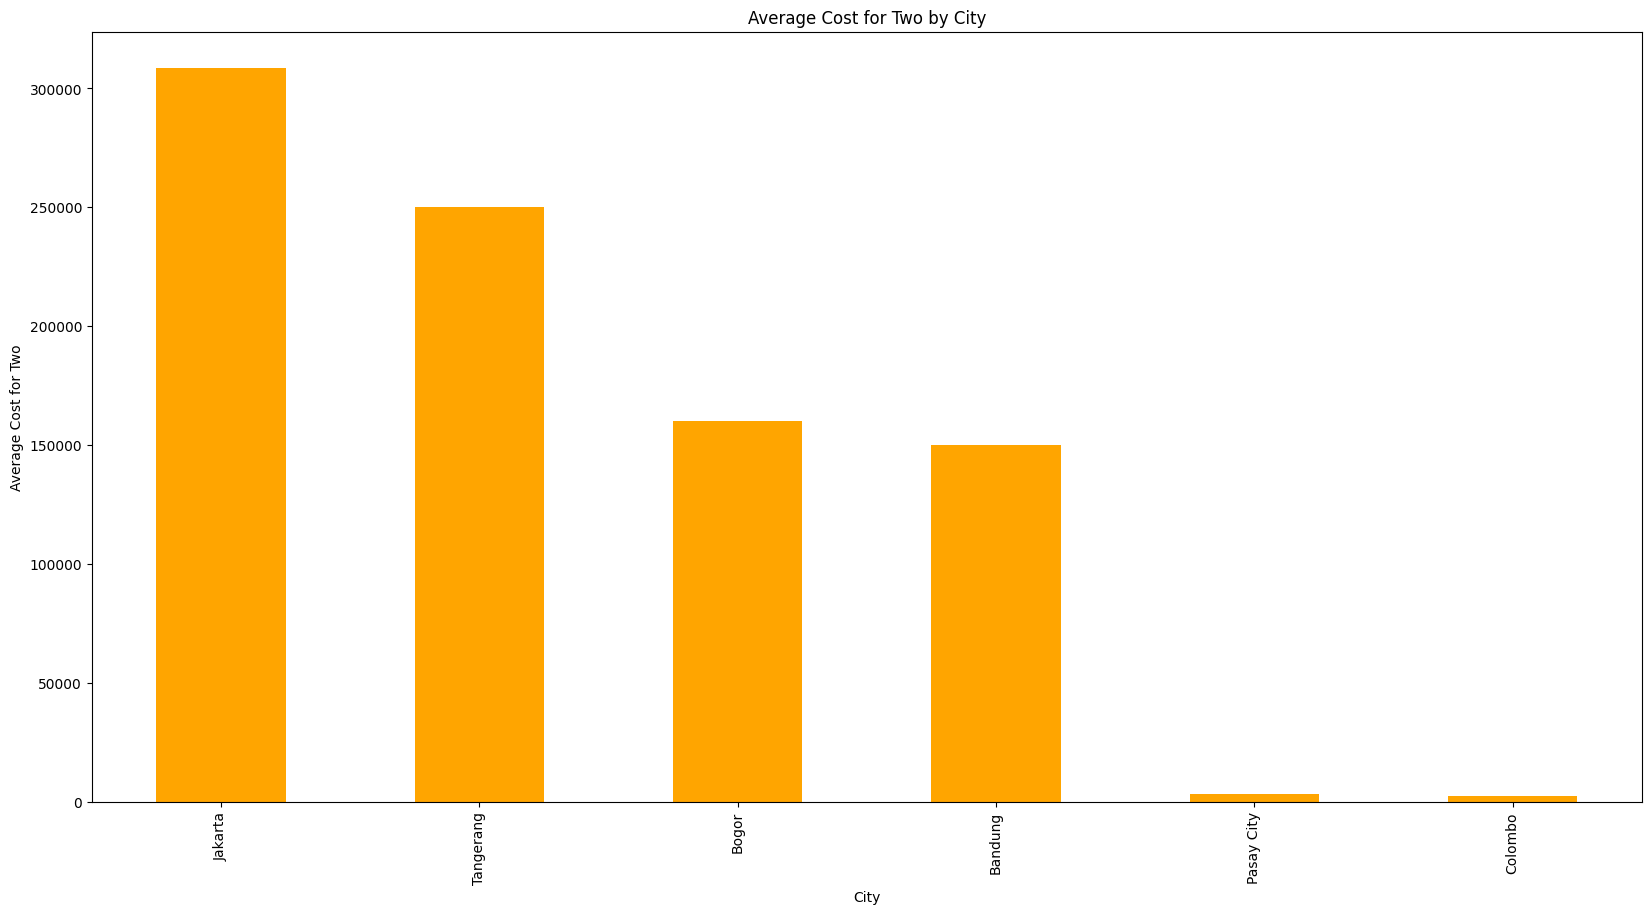

In [4]:
# Average Cost for Two by City
plt.figure(figsize=(20, 10))
df.groupby('City')['Average Cost for two'].mean().sort_values(ascending=False).head(6).plot(kind='bar', color='orange')
plt.title('Average Cost for Two by City')
plt.xlabel('City')
plt.ylabel('Average Cost for Two')
plt.show()

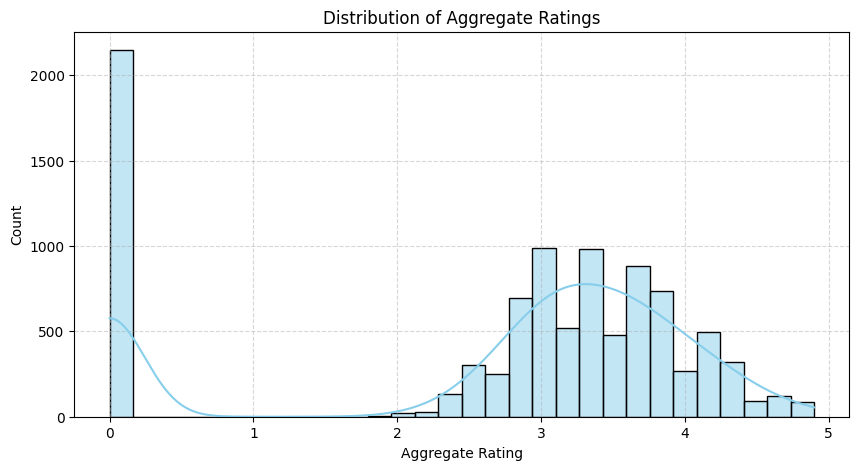

In [15]:
# 1. Target Variable Distribution (Aggregate Rating)
plt.figure(figsize=(10, 5))
sns.histplot(df['Aggregate rating'], bins=30, kde=True, color='skyblue')
plt.title('Distribution of Aggregate Ratings')
plt.xlabel('Aggregate Rating')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

C:\Users\PC\AppData\Local\Temp\ipykernel_5536\3485398112.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Has Table booking', y='Aggregate rating', data=df, ax=axes[0], palette='Set2')
C:\Users\PC\AppData\Local\Temp\ipykernel_5536\3485398112.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Has Online delivery', y='Aggregate rating', data=df, ax=axes[1], palette='Set1')


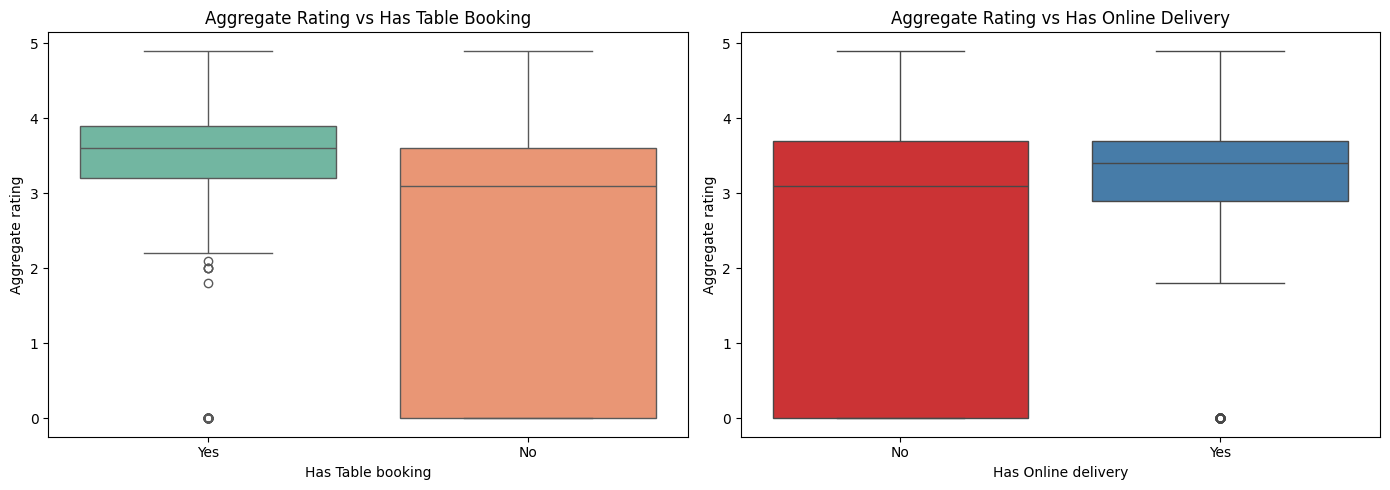

In [16]:
# 2. Analysis of Services vs. Aggregate Rating
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x='Has Table booking', y='Aggregate rating', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Aggregate Rating vs Has Table Booking')

sns.boxplot(x='Has Online delivery', y='Aggregate rating', data=df, ax=axes[1], palette='Set1')
axes[1].set_title('Aggregate Rating vs Has Online Delivery')

plt.tight_layout()
plt.show()

C:\Users\PC\AppData\Local\Temp\ipykernel_5536\3737888685.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='Price range', y='Aggregate rating', data=df, palette='viridis', ci=None)
C:\Users\PC\AppData\Local\Temp\ipykernel_5536\3737888685.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Price range', y='Aggregate rating', data=df, palette='viridis', ci=None)


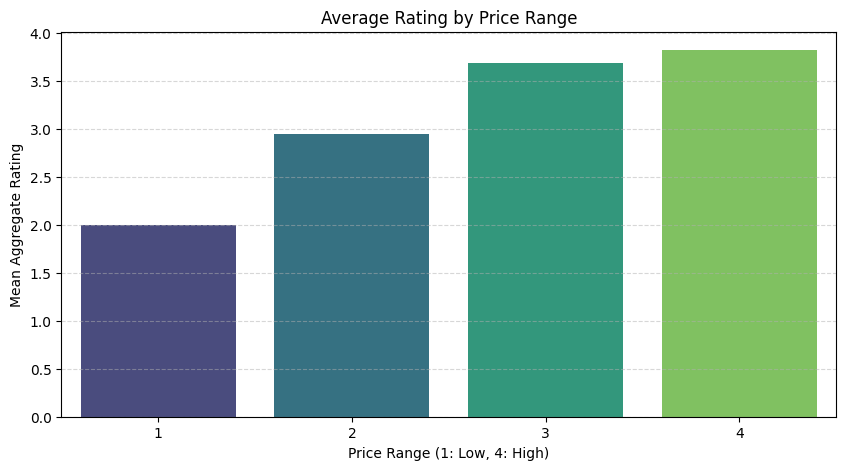

In [19]:
# 3. Price Range vs. Aggregate Rating
plt.figure(figsize=(10, 5))
sns.barplot(x='Price range', y='Aggregate rating', data=df, palette='viridis', ci=None)
plt.title('Average Rating by Price Range')
plt.xlabel('Price Range (1: Low, 4: High)')
plt.ylabel('Mean Aggregate Rating')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


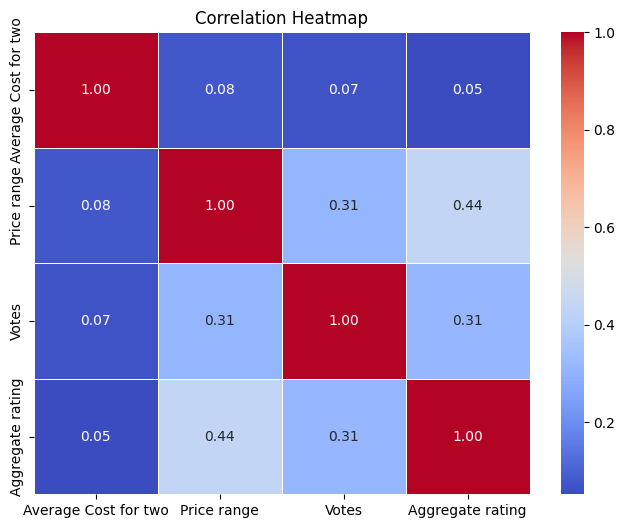

In [18]:
# 4. Correlation Matrix
plt.figure(figsize=(8, 6))
numeric_df = df[['Average Cost for two', 'Price range', 'Votes', 'Aggregate rating']].corr()
sns.heatmap(numeric_df, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

In [5]:
# Selecting features and target variable
x = df[['Average Cost for two', 'Has Table booking', 'Has Online delivery', 'Price range']].copy()
y = df['Aggregate rating']

# Encoding categorical columns safely without SettingWithCopyWarning
label_encoder = LabelEncoder()
x.loc[:, 'Has Table booking'] = label_encoder.fit_transform(x['Has Table booking'])
x.loc[:, 'Has Online delivery'] = label_encoder.fit_transform(x['Has Online delivery'])

# Feature Scaling
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

# Train Test Split
x_train, x_test, y_train, y_test = train_test_split(x_scaled, y, test_size=0.2, random_state=42)

In [6]:
# Linear Regression Model
lr = LinearRegression()
lr.fit(x_train, y_train)
y_pred = lr.predict(x_test)

print('Mean Squared Error:', mean_squared_error(y_test, y_pred))
print('Root Mean Squared Error:', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R2 Score:', r2_score(y_test, y_pred))

Mean Squared Error: 1.7409747034700305
Root Mean Squared Error: 1.3194600044980638
R2 Score: 0.2351092540461741


In [7]:
# Random Forest Regressor Model
rf = RandomForestRegressor(random_state=42)
rf.fit(x_train, y_train)
y_pred_rf = rf.predict(x_test)

print('Random Forest - Mean Squared Error:', mean_squared_error(y_test, y_pred_rf))
print('Random Forest - Root Mean Squared Error:', np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print('Random Forest - R2 Score:', r2_score(y_test, y_pred_rf))

Random Forest - Mean Squared Error: 1.5201208889521667
Random Forest - Root Mean Squared Error: 1.2329318265630775
Random Forest - R2 Score: 0.33214055415444976


In [8]:
# Gradient Boosting Regressor Model
gb = GradientBoostingRegressor(random_state=42)
gb.fit(x_train, y_train)
y_pred_gb = gb.predict(x_test)

print('Gradient Boosting - Mean Squared Error:', mean_squared_error(y_test, y_pred_gb))
print('Gradient Boosting - Root Mean Squared Error:', np.sqrt(mean_squared_error(y_test, y_pred_gb)))
print('Gradient Boosting - R2 Score:', r2_score(y_test, y_pred_gb))

Gradient Boosting - Mean Squared Error: 1.5148957942691301
Gradient Boosting - Root Mean Squared Error: 1.230811031096622
Gradient Boosting - R2 Score: 0.3344361800253032


In [9]:
# Decision Tree Regressor Model
dt = DecisionTreeRegressor(random_state=42)
dt.fit(x_train, y_train)
y_pred_dt = dt.predict(x_test)

print('Decision Tree - Mean Squared Error:', mean_squared_error(y_test, y_pred_dt))
print('Decision Tree - Root Mean Squared Error:', np.sqrt(mean_squared_error(y_test, y_pred_dt)))
print('Decision Tree - R2 Score:', r2_score(y_test, y_pred_dt))

Decision Tree - Mean Squared Error: 1.5223565332635727
Decision Tree - Root Mean Squared Error: 1.2338381309003108
Decision Tree - R2 Score: 0.33115833216028145


In [10]:
# Extra Trees Regressor Model
et = ExtraTreesRegressor(random_state=42)
et.fit(x_train, y_train)
y_pred_et = et.predict(x_test)

print('Extra Trees - Mean Squared Error:', mean_squared_error(y_test, y_pred_et))
print('Extra Trees - Root Mean Squared Error:', np.sqrt(mean_squared_error(y_test, y_pred_et)))
print('Extra Trees - R2 Score:', r2_score(y_test, y_pred_et))

Extra Trees - Mean Squared Error: 1.5169977693375631
Extra Trees - Root Mean Squared Error: 1.2316646334686903
Extra Trees - R2 Score: 0.3335126851147422


In [11]:
# AdaBoost Regressor Model
ada = AdaBoostRegressor(random_state=42)
ada.fit(x_train, y_train)
y_pred_ada = ada.predict(x_test)

print('AdaBoost - Mean Squared Error:', mean_squared_error(y_test, y_pred_ada))
print('AdaBoost - Root Mean Squared Error:', np.sqrt(mean_squared_error(y_test, y_pred_ada)))
print('AdaBoost - R2 Score:', r2_score(y_test, y_pred_ada))

AdaBoost - Mean Squared Error: 1.6659946035076751
AdaBoost - Root Mean Squared Error: 1.2907341335486853
AdaBoost - R2 Score: 0.26805148145337754


In [12]:
# K-Neighbors Regressor Model
knn = KNeighborsRegressor()
knn.fit(x_train, y_train)
y_pred_knn = knn.predict(x_test)

print('K-NN - Mean Squared Error:', mean_squared_error(y_test, y_pred_knn))
print('K-NN - Root Mean Squared Error:', np.sqrt(mean_squared_error(y_test, y_pred_knn)))
print('K-NN - R2 Score:', r2_score(y_test, y_pred_knn))

K-NN - Mean Squared Error: 1.7129266352694923
K-NN - Root Mean Squared Error: 1.308788231636231
K-NN - R2 Score: 0.247432068252327


In [13]:
svr = SVR()
svr.fit(x_train, y_train)
y_pred_svr = svr.predict(x_test)

print('SVR - Mean Squared Error:', mean_squared_error(y_test, y_pred_svr))
print('SVR - Root Mean Squared Error:', np.sqrt(mean_squared_error(y_test, y_pred_svr)))
print('SVR - R2 Score:', r2_score(y_test, y_pred_svr))

SVR - Mean Squared Error: 2.0735574278276916
SVR - Root Mean Squared Error: 1.4399852179198547
SVR - R2 Score: 0.08899027390347025


In [17]:
# Ridge Regressor Model
ridge = Ridge()
ridge.fit(x_train, y_train)
y_pred_ridge = ridge.predict(x_test)

print('Ridge Regression - Mean Squared Error:', mean_squared_error(y_test, y_pred_ridge))
print('Ridge Regression - Root Mean Squared Error:', np.sqrt(mean_squared_error(y_test, y_pred_ridge)))
print('Ridge Regression - R2 Score:', r2_score(y_test, y_pred_ridge))

Ridge Regression - Mean Squared Error: 1.7409781178815198
Ridge Regression - Root Mean Squared Error: 1.3194612983644196
Ridge Regression - R2 Score: 0.2351077539372145
